### Ensemble

In [1]:
# ======================
# Básicas
# ======================
import pandas as pd
import numpy as np

# ======================
# Visualización
# ======================
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from pandas.plotting import scatter_matrix

# ======================
# Preprocesado
# ======================
from sklearn.preprocessing import (
    LabelEncoder,
    OneHotEncoder,
    StandardScaler
)
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import (
    VarianceThreshold,
    SelectKBest
)

# ======================
# Modelos
# ======================
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    BaggingClassifier,
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier
)

import xgboost
from xgboost import XGBClassifier

# ======================
# Pipelines e imbalance
# ======================
from sklearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

# ======================
# Validación y búsqueda
# ======================
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    cross_validate,
    GridSearchCV
)

# ======================
# Métricas
# ======================
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc,
    RocCurveDisplay
)


In [2]:
df_bank=pd.read_csv('bank-full.csv', sep=';')

In [3]:
df_bank.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [4]:
df_bank.y.value_counts()

,count
y,
no,39922
yes,5289


In [5]:
df_bank.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [6]:
df_bank.dtypes

,0
age,int64
job,object
marital,object
education,object
default,object
balance,int64
housing,object
loan,object
contact,object
day,int64


In [7]:
lista_numericas=['age','balance','duration','day','pdays','previous','campaign']

In [8]:
lista_categoricas=['job','marital','education','contact','month','poutcome']

In [9]:
categoricas_binarias = ['default','housing','loan','y']

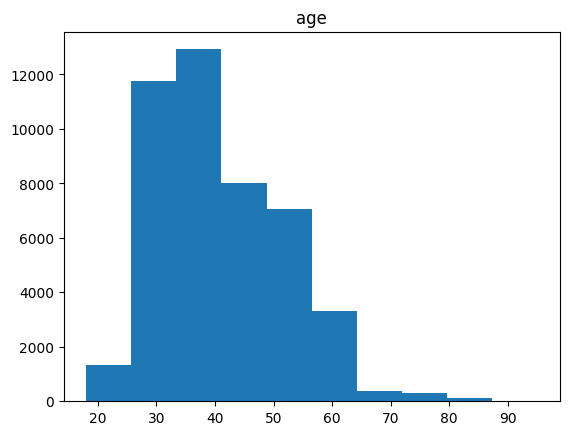

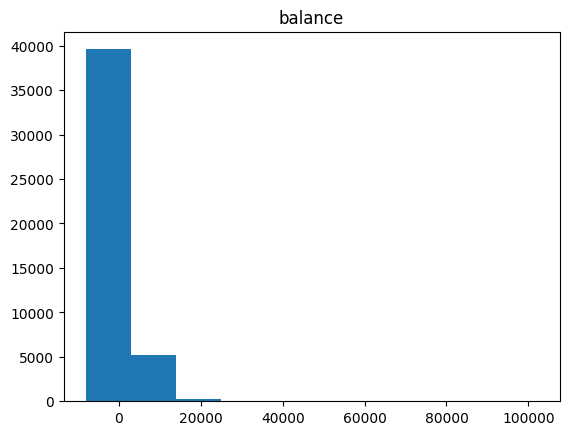

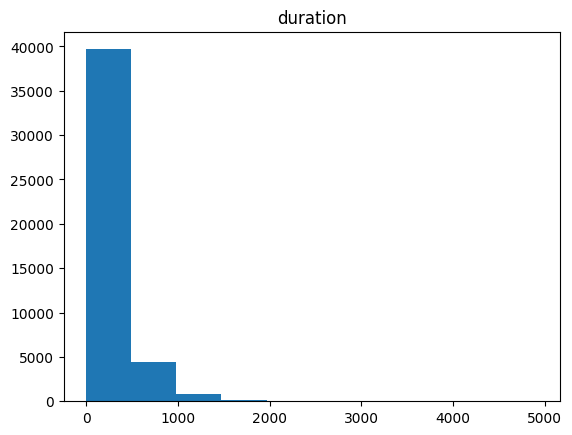

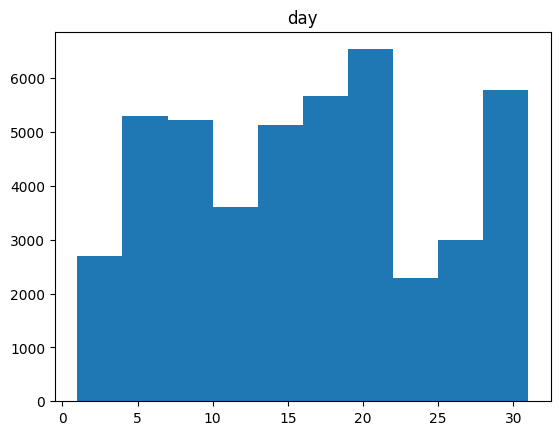

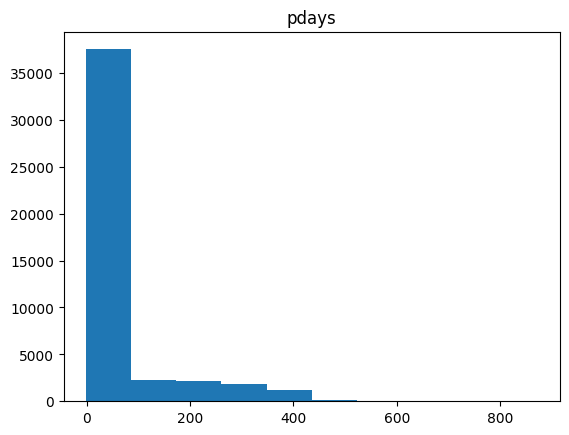

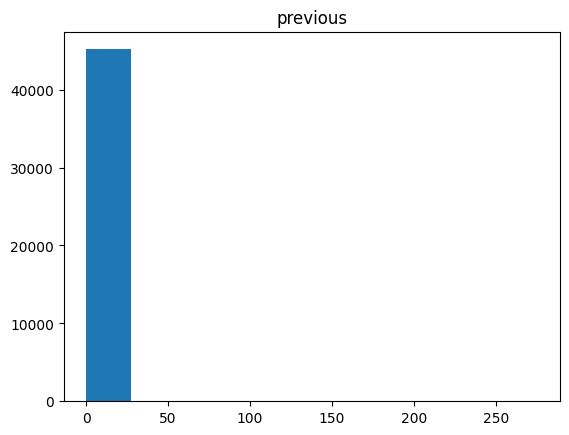

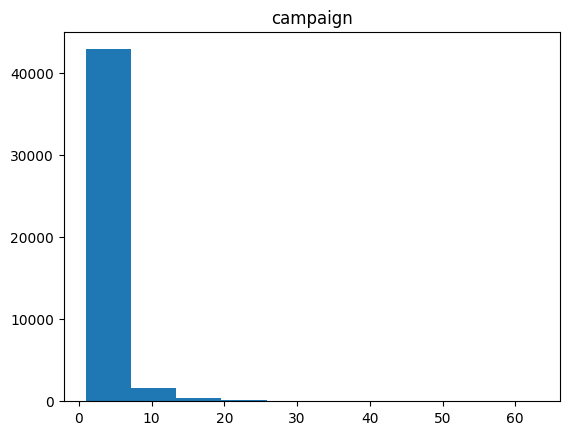

In [10]:
for l in lista_numericas:
    plt.hist(df_bank[l])
    plt.title(l)
    plt.show()

In [11]:
df_bank.isnull().sum()

,0
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0


In [12]:

target = "y"

df_bank[target] = (df_bank[target] == "yes").astype(int)


num_cols = ['age','balance','duration','day','pdays','previous','campaign']
cat_cols = ['job','marital','education','contact','month','poutcome', 'default','housing','loan']

X = df_bank.drop(columns=[target])
y = df_bank[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

preprocess = ColumnTransformer(
    transformers=[
        ("num", Pipeline(steps=[
            ("scaler", StandardScaler())
        ]), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ],
    remainder="drop",
    verbose_feature_names_out=False
)


In [13]:
models = {
    "LogReg (baseline)": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Bagging (DT)": BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=42),
        n_estimators=50,
        random_state=42,
        n_jobs=-1
    ),
    "RandomForest": RandomForestClassifier(
        n_estimators=50,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced_subsample"
    ),
    "ExtraTrees": ExtraTreesClassifier(
        n_estimators=50,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced"
    )
}

try:
    from xgboost import XGBClassifier
    models["XGBoost"] = XGBClassifier(
        n_estimators=50,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        reg_lambda=1.0,
        random_state=42,
        n_jobs=-1,
        eval_metric="logloss"
    )
except Exception as e:
    print("XGBoost no disponible:", e)


In [14]:
# Voting y Stacking (se montan a partir de otros estimadores)
vote_estimators = [
    ("rf", models["RandomForest"]),
    ("et", models["ExtraTrees"]),
    ("xgb", models["XGBoost"])
]
models["Voting (soft)"] = VotingClassifier(
    estimators=vote_estimators,
    voting="soft",
    n_jobs=-1
)

models["Stacking"] = StackingClassifier(
    estimators=vote_estimators,
    final_estimator=LogisticRegression(max_iter=2000, class_weight="balanced"),
    stack_method="predict_proba",
    passthrough=False,
    n_jobs=-1
)


In [15]:
cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=42)

scoring = {
    #"accuracy": "accuracy",
    #"precision": "precision",
    #"recall": "recall",
    "f1": "f1",
    #"roc_auc": "roc_auc"
}

def benchmark(models_dict, use_smote=False):
    rows = []
    for name, clf in models_dict.items():
        if use_smote:
            pipe = ImbPipeline(steps=[
                ("preprocess", preprocess),
                ("smote", SMOTE(random_state=42)),
                ("model", clf)
            ])
        else:
            pipe = Pipeline(steps=[
                ("preprocess", preprocess),
                ("model", clf)
            ])

        scores = cross_validate(
            pipe, X_train, y_train,
            cv=cv, scoring=scoring,
            n_jobs=-1,
            return_train_score=False
        )
        row = {"model": name}
        for k, v in scores.items():
            if k.startswith("test_"):
                metric = k.replace("test_", "")
                row[f"{metric}_mean"] = float(np.mean(v))
                row[f"{metric}_std"]  = float(np.std(v))
        rows.append(row)

    df = pd.DataFrame(rows)
    return df

results_no_smote = benchmark(models, use_smote=False)
results_no_smote


,model,f1_mean,f1_std
0,LogReg (baseline),0.550662,0.009121
1,Bagging (DT),0.528521,0.011034
2,RandomForest,0.406311,0.002496
3,ExtraTrees,0.410225,0.004363
4,XGBoost,0.358195,0.006698
5,Voting (soft),0.381302,0.000837
6,Stacking,0.593458,0.003754


In [16]:
results_smote = benchmark(models, use_smote=True)
results_smote

,model,f1_mean,f1_std
0,LogReg (baseline),0.548867,0.005193
1,Bagging (DT),0.577778,0.005134
2,RandomForest,0.542935,0.009670
3,ExtraTrees,0.479707,0.003595
4,XGBoost,0.539043,0.004163
5,Voting (soft),0.578694,0.008861
6,Stacking,0.446321,0.006110


Mejor modelo (CV): LogReg (baseline)
              precision    recall  f1-score   support

           0       0.97      0.85      0.91      7985
           1       0.42      0.81      0.55      1058

    accuracy                           0.85      9043
   macro avg       0.70      0.83      0.73      9043
weighted avg       0.91      0.85      0.87      9043

Confusion matrix:
 [[6786 1199]
 [ 196  862]]


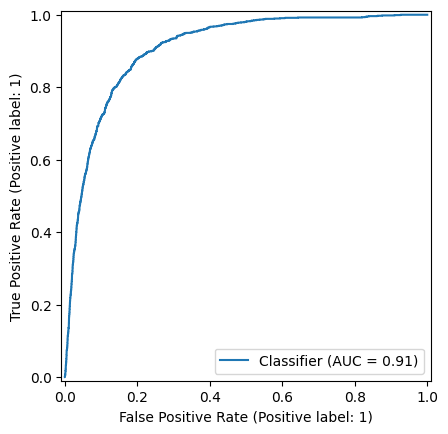

In [17]:
best_name = results_no_smote.iloc[0]["model"]
best_clf = models[best_name]

best_pipe = Pipeline(steps=[
    ("preprocess", preprocess),
    ("model", best_clf)
]).fit(X_train, y_train)

y_pred = best_pipe.predict(X_test)
y_proba = best_pipe.predict_proba(X_test)[:, 1] if hasattr(best_pipe, "predict_proba") else None

print("Mejor modelo (CV):", best_name)
print(classification_report(y_test, y_pred))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))

if y_proba is not None:
    RocCurveDisplay.from_predictions(y_test, y_proba)
    plt.show()
